<a href="https://colab.research.google.com/github/IzzaDhafira/Pembelajaran_Mesin_2026/blob/main/T11_244107020106_IzzaDhafiraFanani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**
Klasifikasi SVM dengan Data Dummy Linier

Langkah 1 - Import Library

In [71]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

Langkah 2 - Membuat Data Dummy

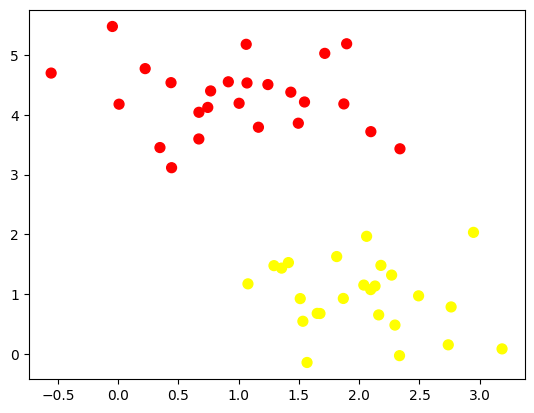

In [72]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

Langkah 3 - Buat Ilustrasi Garis Pemisah

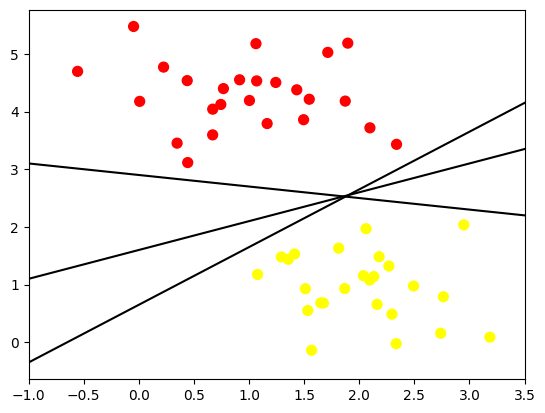

In [73]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Membuat beberapa garis pemisah dengan kemiringan (slope) dan intercept berbeda
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)
plt.show()

Langkah 4 - Ilustrasi Margin

(-1.0, 3.5)

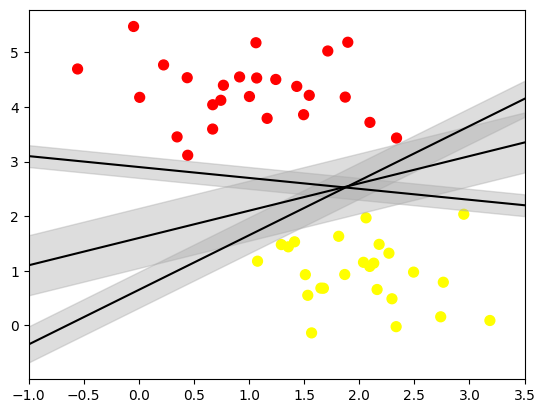

In [4]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)

Langkah 5 - Fitting Model

In [74]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

In [6]:
# Selanjutnya buat fungsi untuk membantu visualisasi hasil fit model
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

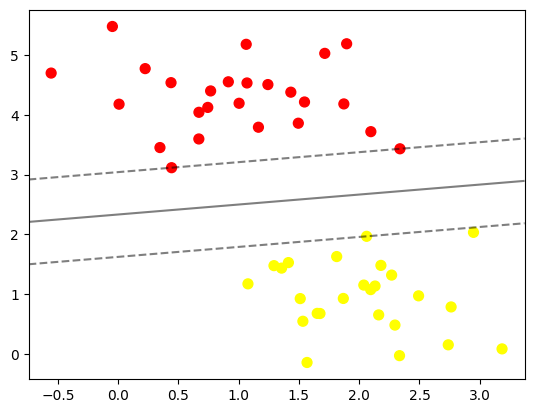

In [7]:
# Lakukan plotting dengan fungsi yang telah dibuat
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

In [8]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

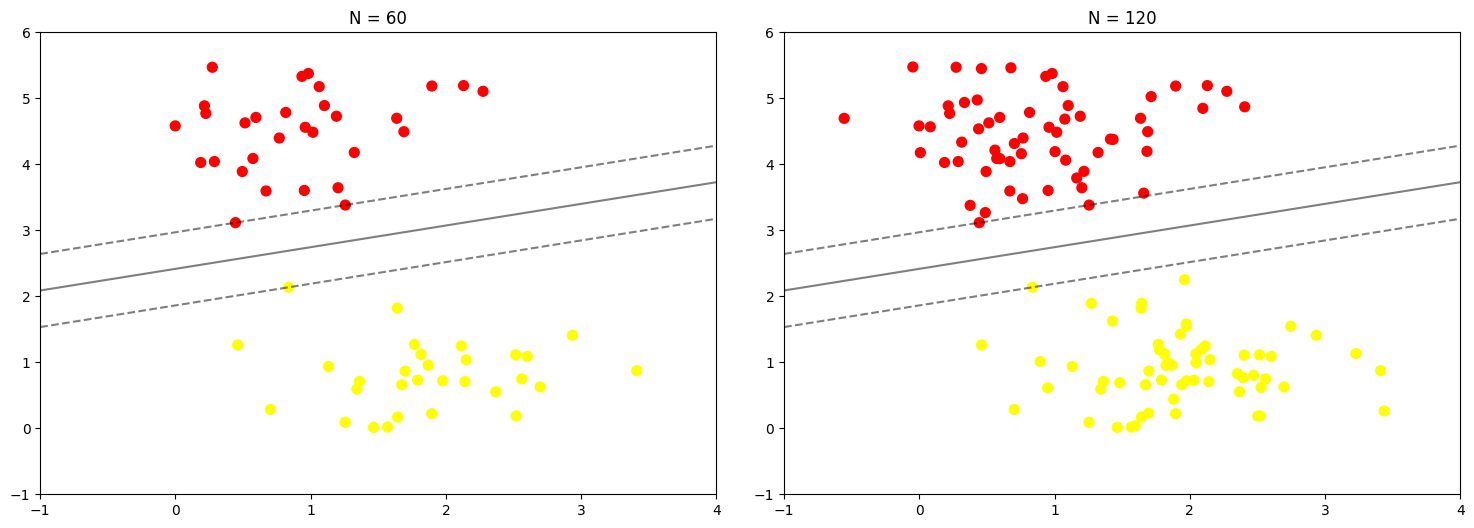

In [9]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

In [10]:
# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

# **PRAKTIKUM 2**
Klasifikasi SVM dengan Data Dummy Non-Linier

Langkah 1 - Ilustrasi Data Non-Linier

In [75]:
# Langkah 1a - Import Library
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [12]:
# Langkah 1b - Buat Kembali Fungsi Plotting
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

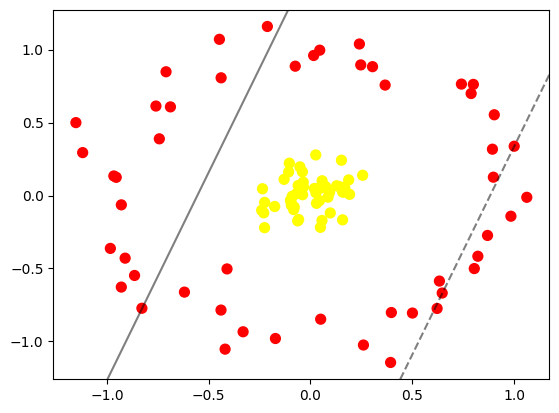

In [13]:
# Langkah 1c - Buat Data Dummy Non-Linier
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-0.98293095, -0.36235686],
       [ 0.1686093 ,  0.04999498],
       [ 0.6220013 , -0.77389094],
       [-0.03968297,  0.16279949],
       [ 0.02675213,  0.01917254],
       [-0.1295605 ,  0.11103181],
       [-0.7423863 ,  0.38857568],
       [-0.0955041 , -0.0437922 ],
       [ 0.04430371, -0.03488855],
       [-0.22552572, -0.22038197],
       [-0.92902574, -0.06391173],
       [-0.08972868, -0.00514172],
       [-0.40985935, -0.50290404],
       [ 0.15730918,  0.02583268],
       [ 0.04552151,  0.99617943],
       [-0.17582254, -0.07508811],
       [ 0.0260769 ,  0.27822549],
       [ 0.05709928,  0.10119194],
       [-0.23969727, -0.10105883],
       [-0.03552277,  0.09133519],
       [-0.17210671, -0.97978653],
       [-0.22946103, -0.11868383],
       [ 0.25634571,  0.13893373],
       [-0.70938064,  0.84814662],
       [ 0.12853093,  0.06701255],
       [-0.68783655,  0.60755137],
       [ 0.39362323, -1.14410328],
       [-0.43943405, -0.78488724],
       [-0.0980886 , -0.03234846],
       [-0.4472627 ,  1.07055088],
       [ 0.05662536, -0.17101396],
       [ 0.19199516,  0.00820641],
       [ 0.86970186, -0.27351778],
       [ 0.82220101, -0.4161142 ],
       [ 0.89844027,  0.12568903],
       [ 0.30481983,  0.88312232],
       [-0.06287325, -0.17368337],
       [ 0.89382623,  0.3175683 ],
       [-0.33093177, -0.93370093],
       [-0.8280223 , -0.77247596],
       [ 0.80009471,  0.76167859],
       [ 0.0937377 ,  0.02140253],
       [ 0.63338657, -0.58611963],
       [-0.07482103,  0.88645279],
       [ 0.01954992,  0.04854136],
       [ 0.90288529,  0.55345123],
       [-1.11896961,  0.29417709],
       [-0.06047327,  0.06893199],
       [ 0.05076472,  0.05080348],
       [-0.43888333,  0.80672849],
       [-0.22506712, -0.04714509],
       [-0.03871128,  0.00560123],
       [ 0.2469482 ,  0.89510255],
       [-0.7591032 ,  0.61326939],
       [ 0.01562285,  0.95968675],
       [-0.92918895, -0.62738507],
       [-0.03436444,  0.05906585],
       [ 0.05013235, -0.84741389],
       [-0.10386004,  0.22192566],
       [-0.09401763, -0.0661991 ],
       [ 0.64702028, -0.6681342 ],
       [-0.95410598,  0.12486532],
       [ 0.26018242, -1.02444182],
       [ 1.0006893 ,  0.33791943],
       [ 0.74142057,  0.76374151],
       [ 0.78914536,  0.69914195],
       [ 0.50089739, -0.80529162],
       [ 0.08629936, -0.01108009],
       [-0.05423839,  0.01957773],
       [-1.15223751,  0.49974521],
       [ 0.24031342,  1.03851853],
       [ 0.80468711, -0.50055621],
       [ 0.02757537,  0.04363844],
       [ 0.3666956 ,  0.75696955],
       [-0.23558471,  0.04653598],
       [-0.96586094,  0.13417791],
       [ 0.18777528,  0.10713876],
       [-0.41933024, -1.05268169],
       [-0.2117459 ,  1.15855682],
       [ 0.98453534, -0.14169455],
       [ 1.06261391, -0.01216128],
       [-0.61908321, -0.66187726],
       [-0.05202176,  0.19652831],
       [-0.08271627, -0.09631747],
       [ 0.15781234, -0.16640475],
       [ 0.04897177, -0.21795953],
       [ 0.14362359,  0.06025467],
       [-0.07970432, -0.07880237],
       [-0.10709327,  0.16201995],
       [ 0.0294723 , -0.05349955],
       [ 0.1607984 ,  0.02295418],
       [ 0.16514943,  0.05635769],
       [ 0.39734279, -0.80179272],
       [ 0.07451256,  0.06113656],
       [ 0.09724265, -0.11930998],
       [ 0.15219895,  0.2418478 ],
       [-0.91034365, -0.42920253],
       [-0.05804728, -0.16435396],
       [-0.06862925,  0.01264222],
       [-0.86408667, -0.54783391]]), y=array([0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0]))>

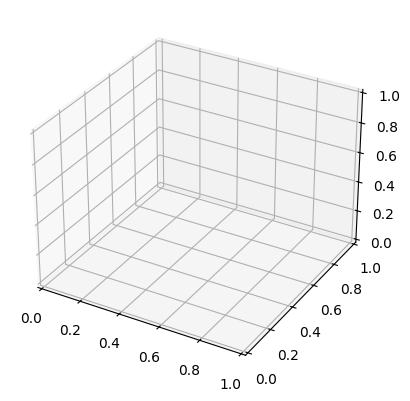

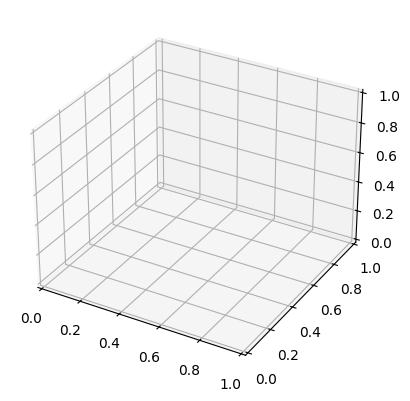

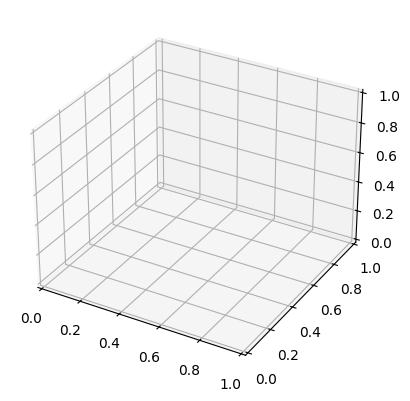

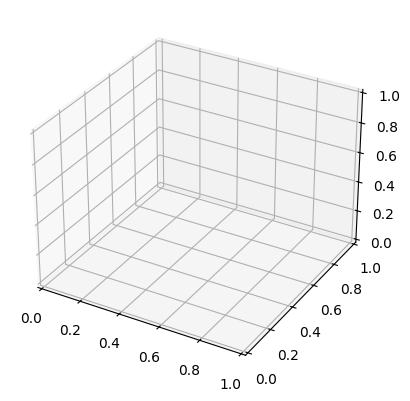

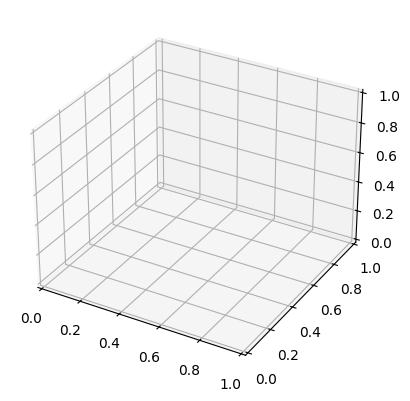

In [14]:
# Karena proyeksi radial tidak cukup menggunakan model 2D, maka plot visualisasi diubah menjadi model 3D
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))

Langkah 2 - Fitting Model

In [76]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

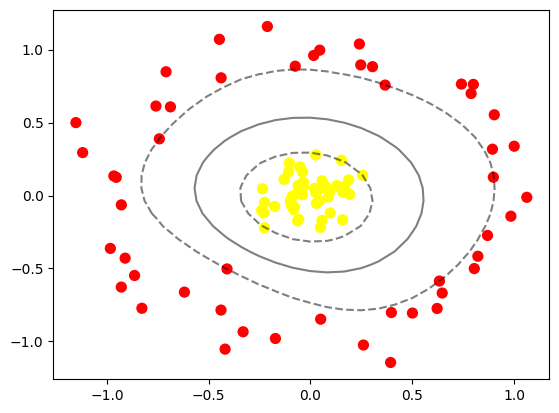

In [16]:
# Plot hasil decision boundaries dari kernel RBF
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')

# **PRAKTIKUM 3**
SVM Data Overlapping

Langkah 1 - Import Library dan Buat Fungsi Plotting

In [77]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

Langkah 2 - Buat Data Dummy

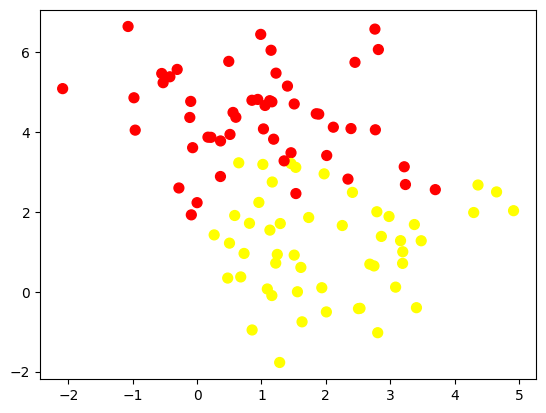

In [78]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

Langkah 3 - Analisis Dampak Tunning

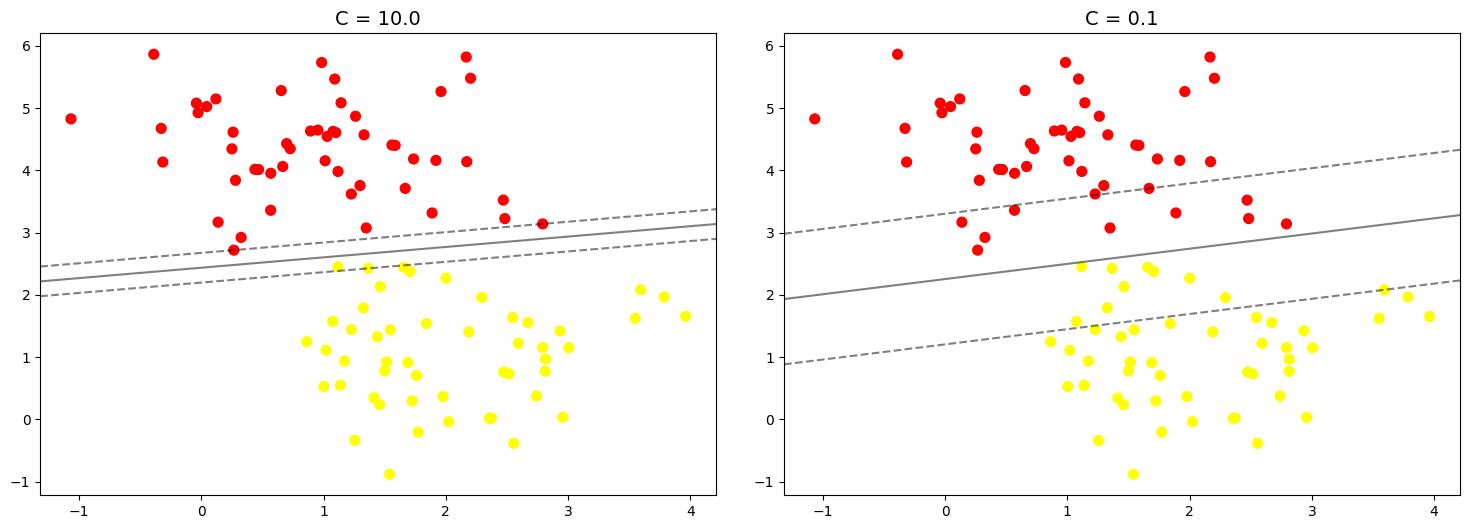

In [79]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

# **PRAKTIKUM 4**
Klasifikasi Citra Wajah

Langkah 0 - Unduh Dataset

In [80]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


Langkah 1 - Inspeksi Citra Wajah

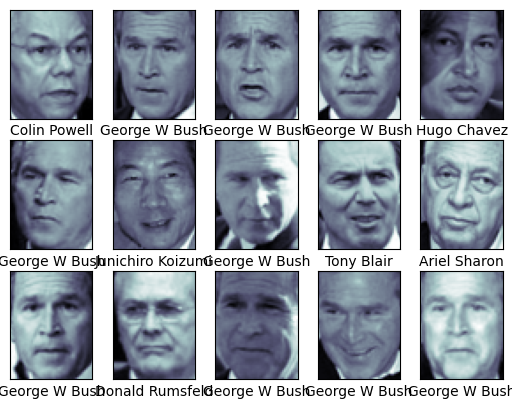

In [81]:
# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

Langkah 2 - Pra Pengolahan Data

In [82]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

Langkah 3 - Split Data

In [83]:
# pemisahan data training dan data testing

from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

Langkah 4 - Pembuatan Model + Tunning

In [84]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 2min 4s, sys: 156 ms, total: 2min 4s
Wall time: 1min 47s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [26]:
# Gunakan model terbaik tersebut untuk proses prediksi
model = grid.best_estimator_
yfit = model.predict(Xtest)

Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

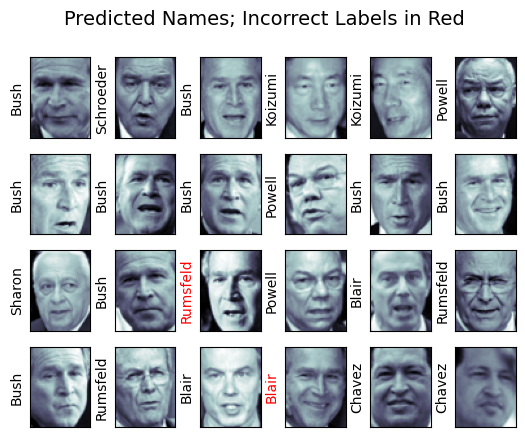

In [85]:
# hasil label pada data testing

fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

Langkah 6 - Cek Performansi

In [86]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Text(113.92222222222219, 0.5, 'predicted label')

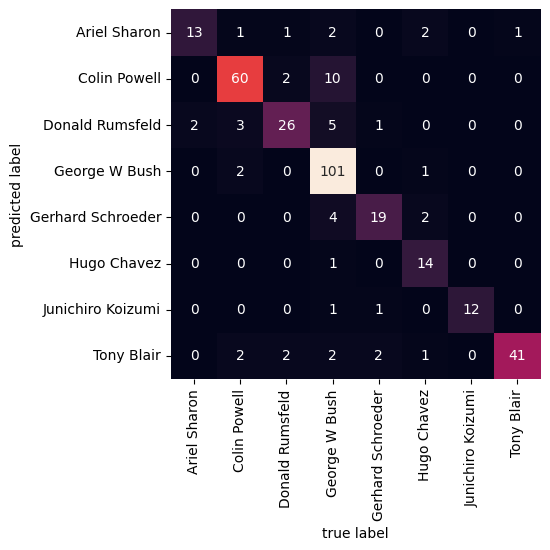

In [29]:
# Selanjutnya, kita dapat menggunakan confusion matrix untuk mengetahui label label yang terklasifikasi  dengan benar dan tidak
# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')

# **PRAKTIKUM 5**
Klasifikasi Citra Siang dan Malang

Langkah 0 - Import Library

In [87]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [35]:
import zipfile
import os

# 1. Ekstrak file images.zip
zip_path = 'images.zip'
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('./')
    print("Ekstraksi selesai! Folder 'images' berhasil dibuat.")
else:
    print("File images.zip tidak ditemukan. Pastikan Anda sudah mengunggah file tersebut ke panel sebelah kiri.")

# 2. Muat ulang dataset training
train_img = load_dataset(train_dir)
print(f"Jumlah gambar yang berhasil dimuat: {len(train_img)}")

Ekstraksi selesai! Folder 'images' berhasil dibuat.
Jumlah gambar yang berhasil dimuat: 240


In [31]:
# Lakukan ekstraksi data gambar
# Image directories
train_dir = "images/training/"
test_dir = "images/test/"

Langkah 1 - Load Data dan Visualisasikan

In [88]:
# Buatlah fungsi untuk membuat daftar seluruh path dari gambar
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if not img is None:
                img_list.append((img, label))

    return img_list

In [33]:
# Load gambar training
# Load training data
train_img = load_dataset(train_dir)

In [36]:
# Lakukan pengecekan pada salah satu data pada list.
# List harus berisi tuple dengan dua data, yaitu data gambar dan label dari gambar.
train_img[0]

(array([[[22, 24, 23],
         [21, 23, 22],
         [20, 22, 21],
         ...,
         [25, 26, 20],
         [24, 25, 19],
         [24, 25, 19]],
 
        [[22, 24, 23],
         [21, 23, 22],
         [20, 22, 21],
         ...,
         [24, 25, 19],
         [23, 24, 18],
         [23, 24, 18]],
 
        [[22, 24, 23],
         [21, 23, 22],
         [20, 22, 21],
         ...,
         [23, 24, 18],
         [22, 23, 17],
         [22, 23, 17]],
 
        ...,
 
        [[11, 13, 12],
         [ 9, 11, 10],
         [ 7,  9,  8],
         ...,
         [ 8, 11,  4],
         [ 8, 11,  4],
         [ 7, 10,  3]],
 
        [[11, 13, 12],
         [ 9, 11, 10],
         [ 7,  9,  8],
         ...,
         [ 8, 11,  4],
         [ 8, 11,  4],
         [ 7, 10,  3]],
 
        [[11, 13, 12],
         [ 9, 11, 10],
         [ 7,  9,  8],
         ...,
         [ 8, 11,  4],
         [ 8, 11,  4],
         [ 7, 10,  3]]], shape=(555, 800, 3), dtype=uint8),
 'night')

In [37]:
# Cek ukuran gambar secara acak
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 109
(591, 800, 3)


In [89]:
# Tampilkan gambar untuk inspeksi secara visual.
# Buatlah fungsi untuk membantu memvisualkan gambar
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Shape	: (469, 640, 3)
Label	: day


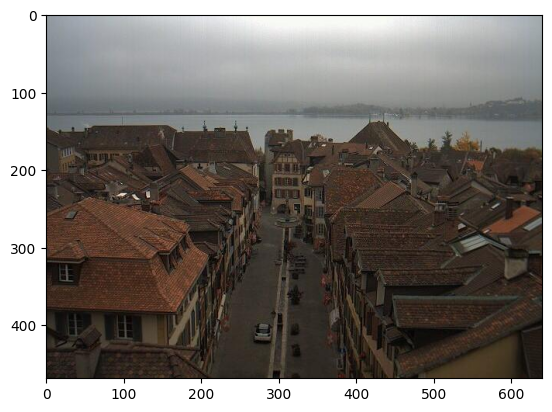

In [49]:
# Lakukan visualisasi gambar secara acak
random_img_viz(train_img)

Langkah 3 - Pra Pengolahan Data

In [90]:
# Bualah fungsi berikut untuk menstandarkan ukuran gambar.
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img

In [44]:
# Selanjutnya, buatlah fungsi untuk kebutuhan encoding label.
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0

    if(label == 'day'):
        num_val = 1

    return num_val

In [45]:
# Terakhir, buatlah fungsi untuk melakukan kedua hal tersebut secara sekaligus untuk semua gambar dalam list.
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [46]:
# Lakukan pra pengolahan data pada data training.
train_std_img_list = preprocess(train_img)

In [47]:
# Lakukan pengecekan ukuran gambar secara acak.
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 28
(600, 1100, 3)


Shape	: (600, 1100, 3)
Label	: 0


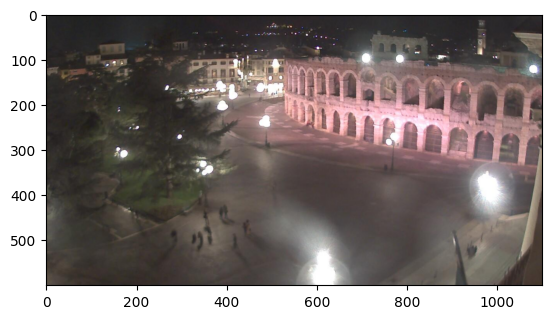

In [55]:
# Jalankan fungsi visualisasi dengan memasukkan dataset yang SUDAH di-preprocess
random_img_viz(train_std_img_list)

Langkah 4 - Ekstraksi Fitur

In [91]:
# Buatlah fungsi berikut untuk mendapatkan nilai rata-rata tingkat kecerahan.
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 220
Avg Brighness: 198.0956


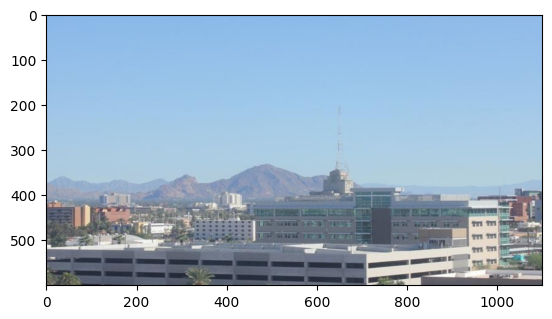

In [57]:
# Lakukan pengecekan pada gambar secara acak. INGAT! Gunakan gambar yang telah melalui proses pra pengolahan data!
# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)

Langkah 5 - Klasifikasi dengan Metode Threshold

In [92]:
# Buatlah fungsi berikut
def predict_label(img, threshold):
    # Computer average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Image 224
Actual label: 1
Predicted label: 1


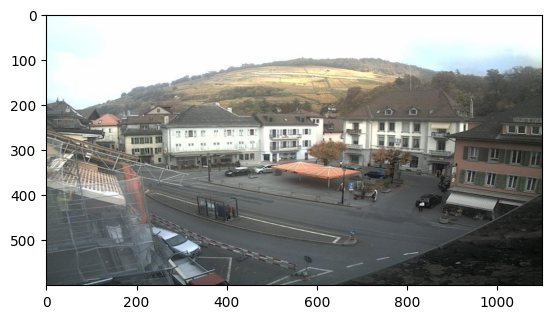

In [62]:
# Lakukan pengecekan prediksi secara acak pada data training
# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

Langkah 6 - Evaluasi Manual

In [93]:
# Buatlah fungsi berikut
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [64]:
#Lakukan evaluasi pada data training dengan nilai ambang batas 120
# Evaluate on train data
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [65]:
# Selanjutnya, kita akan melakukan evaluasi pada data testing.
# Namun sebelumnya, data testing harus diperlakukan sama dengan data training dalam konteks pra progolahan data dan ekstraksi fitur.
# Evaluate on test data

# Load test data
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Predict
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


### **Klasifikasi dengan SVM**

Langkah 4 Alternatif - Membuat Feature Vectors

In [66]:
# Create function to extract feature for every images and stored in tabular data
# Stored in Pandas dataframe
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
        img_label = img[1] # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)

    # Stack data in columcular way
    data = np.column_stack((avg_list, labels))
    # Create a Pandas dataframe
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [67]:
# Extract feature on train data
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,24.730023,0.0
1,108.499220,0.0
2,48.313274,0.0
3,13.972930,0.0
4,97.690179,0.0


In [68]:
# Do the same thing on test data
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,87.567647,0.0
1,26.130920,0.0
2,176.830915,0.0
3,98.786179,0.0
4,47.753383,0.0


Langkah 5 - Buat Model SVM

In [69]:
# import requied library
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

SVC()

Langkah 6 - Evaluasi

In [70]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


# **TUGAS PRAKTIKUM**

1. Buatlah model SVM dengan menggunakan data voice.csv dengan ketentuan,

a. Split data dengan rasio 70:30 dan 80:20 untuk setiap model yang akan dibangun.
* Gunakan model dengan kernel linier.
* Gunakan model dengan kernel polynomial.
* Gunakan model dengan kernel RBF.

b. Tabulasikan performansi setiap split dan kernel berdasarkan metrik akurasi.

In [94]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Load dataset
df_voice = pd.read_csv('/content/voice.csv')
print("Info dataset:")
display(df_voice.info())
display(df_voice.head())

Info dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 n

None

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [95]:
# 2. Preprocessing Data
# Pisahkan fitur dan label
X_voice = df_voice.iloc[:, :-1].values
y_voice = df_voice.iloc[:, -1].values

# Encode label (kategori 'male'/'female' menjadi 0/1)
le = LabelEncoder()
y_voice = le.fit_transform(y_voice)

# Standardisasi fitur agar performa SVM optimal
scaler = StandardScaler()
X_voice_scaled = scaler.fit_transform(X_voice)

In [96]:
# 3. Model Training & Evaluation untuk setiap Split dan Kernel
ratios = [0.3, 0.2]  # Test sizes for 70:30 and 80:20
kernels = ['linear', 'poly', 'rbf']
results = []

for test_size in ratios:
    split_name = f"{int((1 - test_size) * 100)}:{int(test_size * 100)}"

    # Split data
    X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(
        X_voice_scaled, y_voice, test_size=test_size, random_state=42, stratify=y_voice
    )

    for kernel in kernels:
        # Inisialisasi model
        svm_model = SVC(kernel=kernel, random_state=42)
        svm_model.fit(X_train_v, y_train_v)

        # Prediksi
        y_pred_train = svm_model.predict(X_train_v)
        y_pred_test = svm_model.predict(X_test_v)

        # Hitung akurasi
        train_acc = accuracy_score(y_train_v, y_pred_train)
        test_acc = accuracy_score(y_test_v, y_pred_test)

        results.append({
            'Split Ratio': split_name,
            'Kernel': kernel.capitalize(),
            'Train Accuracy': f"{train_acc:.4%}",
            'Test Accuracy': f"{test_acc:.4%}"
        })

In [97]:
# 4. Tampilkan Tabulasi Hasil
df_results = pd.DataFrame(results)
print("Tabulasi Hasil Performansi Model SVM:")
display(df_results)

Tabulasi Hasil Performansi Model SVM:


,Split Ratio,Kernel,Train Accuracy,Test Accuracy
0,70:30,Linear,97.2034%,97.8970%
1,70:30,Poly,96.7975%,95.8991%
2,70:30,Rbf,98.3762%,98.3176%
3,80:20,Linear,97.6322%,97.4763%
4,80:20,Poly,96.8429%,95.7413%
5,80:20,Rbf,98.4215%,98.2650%


2. Gunakan data pada praktikum 5 untuk membuat model klasifikasi siang dan malam menggunakan SVM dengan kernel RBF menggunakan fitur histrogram. Gunakan rasio 80:20. Anda dapat bereksperimen dengan hyperparameter tunning dari kernel RBF. Catat performansi akurasinya!

In [98]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score

# 1. Ekstraksi fitur Histogram warna (3 saluran warna: HSV atau RGB)
def extract_histogram_features(img_list):
    features = []
    labels = []

    for img, label in img_list:
        # Gunakan histogram warna HSV sebagai representasi fitur
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

        # Hitung histogram untuk masing-masing channel H, S, V
        h_hist = cv2.calcHist([hsv], [0], None, [8], [0, 180])
        s_hist = cv2.calcHist([hsv], [1], None, [8], [0, 256])
        v_hist = cv2.calcHist([hsv], [2], None, [8], [0, 256])

        # Gabungkan dan normalisasi histogram
        hist_feature = np.concatenate([h_hist, s_hist, v_hist]).flatten()
        hist_feature = hist_feature / np.sum(hist_feature)

        features.append(hist_feature)
        labels.append(label)

    return np.array(features), np.array(labels)

# Ekstrak fitur histogram dari data train dan test hasil preprocess Praktikum 5
X_train_hist, y_train_hist = extract_histogram_features(train_std_img_list)
X_test_hist, y_test_hist = extract_histogram_features(test_std_img_list)

# Gabungkan seluruh dataset untuk melakukan split mandiri dengan rasio 80:20
X_all = np.vstack((X_train_hist, X_test_hist))
y_all = np.concatenate((y_train_hist, y_test_hist))

# Split data dengan rasio 80:20
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

# Standardisasi fitur histogram
scaler_hist = StandardScaler()
X_train_scaled = scaler_hist.fit_transform(X_train_s)
X_test_scaled = scaler_hist.transform(X_test_s)

print(f"Jumlah data training: {X_train_scaled.shape[0]}")
print(f"Jumlah data testing: {X_test_scaled.shape[0]}")

Jumlah data training: 320
Jumlah data testing: 80


In [99]:
# 2. Hyperparameter Tuning menggunakan GridSearchCV untuk Kernel RBF
param_grid = {
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
}

grid_search = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train_s)

print("Hyperparameter Terbaik:", grid_search.best_params_)
print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

Hyperparameter Terbaik: {'C': 100, 'gamma': 0.001}
Best Cross-Validation Score: 0.9969


In [100]:
# 3. Evaluasi Model SVM RBF Terbaik pada Data Test
best_model = grid_search.best_estimator_
y_pred_train = best_model.predict(X_train_scaled)
y_pred_test = best_model.predict(X_test_scaled)

acc_train = accuracy_score(y_train_s, y_pred_train)
acc_test = accuracy_score(y_test_s, y_pred_test)

print(f"Akurasi Training dengan Model Terbaik : {acc_train:.4%}")
print(f"Akurasi Testing dengan Model Terbaik  : {acc_test:.4%}")
print("\nLaporan Klasifikasi Data Pengujian:")
print(classification_report(y_test_s, y_pred_test))

Akurasi Training dengan Model Terbaik : 99.3750%
Akurasi Testing dengan Model Terbaik  : 100.0000%

Laporan Klasifikasi Data Pengujian:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

